In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Step 1: Load data and Clean

In [132]:
data = pd.read_csv('Housing.csv')

In [133]:
data.shape

(545, 13)

In [134]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB


In [135]:
data.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [136]:
data.duplicated().sum()

np.int64(0)

In [137]:
data.dtypes[data.dtypes == object].drop('furnishingstatus')   # lable encoding

mainroad           object
guestroom          object
basement           object
hotwaterheating    object
airconditioning    object
prefarea           object
dtype: object

In [138]:
data.furnishingstatus.unique()  # ordinal encoding

array(['furnished', 'semi-furnished', 'unfurnished'], dtype=object)

# Univariate Analysis

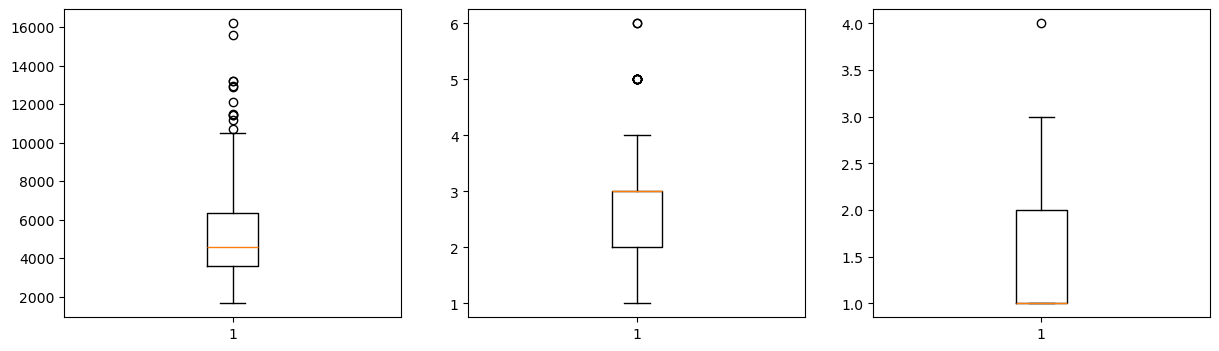

In [139]:
plt.figure(figsize=(20,4))
count = 1
for i in ['area',	'bedrooms',	'bathrooms']:
    plt.subplot(1,4, count)
    plt.boxplot(data[i])
    count+=1

In [221]:
data.shape

(545, 13)

In [227]:
import numpy as np
q1 = np.percentile(data['area'], q=25)
q3 = np.percentile(data['area'], q=75)
iqr = q3 - q1
upb = q3+1.5*iqr
lwb = q1-1.5*iqr
data = data[(data.area < upb) & (data.area > lwb)]

# Bivariate Analysis

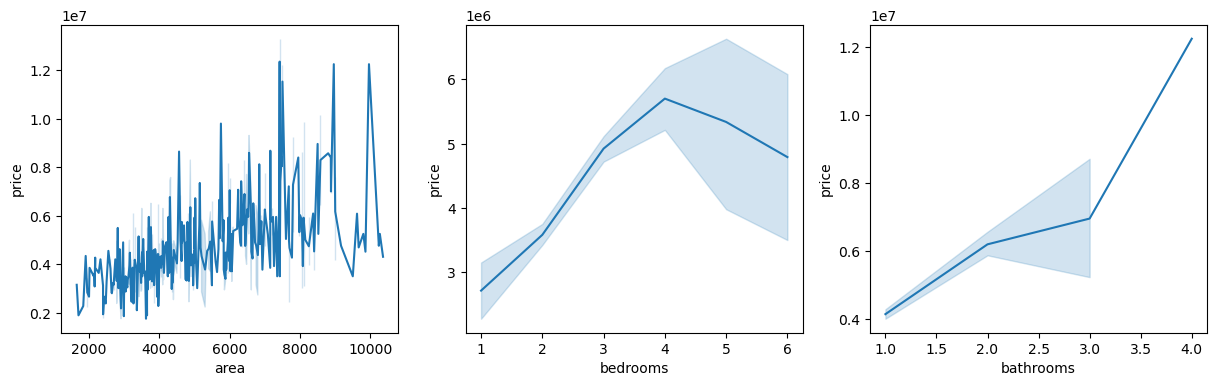

In [228]:
plt.figure(figsize=(20,4))
count = 1
for i in ['area',	'bedrooms',	'bathrooms']:
    plt.subplot(1,4, count)
    sns.lineplot(x= data[i], y= data['price'])
    count += 1

# Step 2: 'Preprocessing'  Encoding columns for their deserving method

In [229]:
import sklearn

In [230]:
df = data.copy()

### Ordinal Encoding

In [231]:
from sklearn.preprocessing import OrdinalEncoder

In [232]:
order = [['unfurnished', 'semi-furnished', 'furnished']]

In [233]:
oe = OrdinalEncoder(categories=order, handle_unknown='use_encoded_value', unknown_value=-1)

In [234]:
df['furnishingstatus']= oe.fit_transform(df[['furnishingstatus']]).astype(int)

### Label Encoding

In [235]:
from sklearn.preprocessing import LabelEncoder

In [236]:
df.columns

Index(['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad',
       'guestroom', 'basement', 'hotwaterheating', 'airconditioning',
       'parking', 'prefarea', 'furnishingstatus'],
      dtype='object')

In [237]:
le = LabelEncoder()

In [238]:
for column in ['mainroad','guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea']:
    df[column] = le.fit_transform(df[column])

### Standard Scaling Normalize area value fo model

In [239]:
from sklearn.preprocessing import StandardScaler

In [240]:
scalar = StandardScaler()

In [241]:
df['area'] = scalar.fit_transform(data[['area']])

In [242]:
df.head(4)

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,1.36,4,2,3,1,0,0,0,1,2,1,2
1,12250000,2.21,4,4,4,1,0,0,0,1,3,0,2
2,12250000,2.77,3,2,2,1,0,1,0,0,2,1,1
3,12215000,1.41,4,2,2,1,0,1,0,1,3,1,2


# Step 3: Correlation

In [243]:
df.corr()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
price,1.00,0.55,0.36,0.52,0.44,0.29,0.27,0.18,0.09,0.46,0.38,0.32,0.30
area,0.55,1.00,0.15,0.22,0.13,0.31,0.21,0.05,-0.03,0.28,0.38,0.24,0.16
bedrooms,0.36,0.15,1.00,0.36,0.41,-0.01,0.09,0.10,0.06,0.17,0.14,0.08,0.14
bathrooms,0.52,0.22,0.36,1.00,0.33,0.04,0.13,0.11,0.08,0.20,0.19,0.07,0.16
stories,0.44,0.13,0.41,0.33,1.00,0.13,0.04,-0.17,0.03,0.31,0.05,0.04,0.11
mainroad,0.29,0.31,-0.01,0.04,0.13,1.00,0.10,0.04,-0.01,0.11,0.20,0.20,0.15
guestroom,0.27,0.21,0.09,0.13,0.04,0.10,1.00,0.38,-0.01,0.14,0.05,0.18,0.13
basement,0.18,0.05,0.10,0.11,-0.17,0.04,0.38,1.00,-0.01,0.04,0.05,0.22,0.10
hotwaterheating,0.09,-0.03,0.06,0.08,0.03,-0.01,-0.01,-0.01,1.00,-0.13,0.07,-0.05,0.02
airconditioning,0.46,0.28,0.17,0.20,0.31,0.11,0.14,0.04,-0.13,1.00,0.16,0.11,0.15


# Step 3: Split data into Training and Testing sets

In [244]:
X = df[['area',	'bedrooms',	'bathrooms',	'stories',	'mainroad',	'guestroom',	'basement',	'airconditioning',	'parking',	'prefarea',	'furnishingstatus']]

In [245]:
y = df['price']

In [246]:
from sklearn.model_selection import train_test_split

In [247]:
x_train, x_test, y_train, y_test = train_test_split(X,y,  test_size=0.2, random_state=42)

# Step 4: Training Model on Train Data

In [248]:
from sklearn.linear_model import LinearRegression

In [249]:
lr = LinearRegression()

In [250]:
lr.fit(x_train,y_train)

LinearRegression()

In [251]:
lr.intercept_

np.float64(1223892.2674263194)

In [252]:
lr.coef_

array([ 504922.81770213,   94664.72875046, 1024999.44688266,
        419667.35462936,  371723.04210551,  456288.41380043,
        269709.92913171,  810248.67302438,  188875.70858764,
        550455.11834722,  121921.36081355])

In [253]:
df.columns

Index(['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad',
       'guestroom', 'basement', 'hotwaterheating', 'airconditioning',
       'parking', 'prefarea', 'furnishingstatus'],
      dtype='object')

### Our Mdel Equation is :---> 

(512414.8(area) + 79698.1(bedrooms) + 1109662.1(bathrooms) + 417838.1(stories) + 355376.2(mainroad) + 226650.6(guestroom) +  405046.6(basement) + 727313.6(airconditioning) + 240331.1(parking) + 612209.9(prefarea) + 217610.2(furnishingstatus)) - 1093827.6

# Step 5: Testing Data on Training sets or Testing Sets also and Model Evaluation

In [254]:
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error, root_mean_squared_error

### ON Tarining Set

In [255]:
x_train_predict = lr.predict(x_train)

In [272]:
print(f"""R2_Score = {r2_score(y_train,x_train_predict)}
MSE      = {mean_squared_error(y_train,x_train_predict)}
RMSE     = {root_mean_squared_error(y_train,x_train_predict)}
MAE      = {mean_absolute_error(y_train,x_train_predict)}""")

R2_Score = 0.6681425140575872
MSE      = 1004199311824.6383
RMSE     = 1002097.4562509569
MAE      = 731480.2748349333


In [257]:
pd.set_option('display.float_format', lambda x: '%.2f' % x)
pd.DataFrame({'Original':y_train, 'Predicted':x_train_predict}).head(3)

,Original,Predicted
148,5600000,5229139.94
541,1767150,2363858.92
432,3290000,4603651.02


### On Testing Set

In [258]:
x_test_predict = lr.predict(x_test)

In [274]:
print(f"""R2_Score = {r2_score(y_test,x_test_predict)}
MSE      = {mean_squared_error(y_test,x_test_predict)} 
RMSE     = {root_mean_squared_error(y_test,x_test_predict)}
MAE      = {mean_absolute_error(y_test,x_test_predict)}""")

R2_Score = 0.6341547250486776
MSE      = 1828778768787.0344 
RMSE     = 1352323.4704711128
MAE      = 917095.1931405006


In [275]:
pd.set_option('display.float_format', lambda x: '%.2f' % x)
pd.DataFrame({'Original':y_test, 'Predicted':x_test_predict}).head(3)

,Original,Predicted
151,5565000,5545827.92
413,3430000,4753064.25
6,10150000,9600250.12


### Final Vedict:
   Our model is GOOD-FIT Model bcz the gap of r2_score between training prediction and testing prediction is 3.5% which is good and show that the model is actually learn from data and give answer accurately on unseen data